In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from xgboost import XGBRegressor

import joblib

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(
    "../reports/forecasting_features.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,DayOfYear,WeekOfYear,IsWeekend,lag_7,lag_14,lag_30,rolling_mean_7,rolling_mean_30,rolling_std_7,rolling_std_30
0,2022-01-31,S001,P0001,Clothing,West,410,200,152,212.24,70.78,...,31,5,0,9.0,69.0,127.0,97.857143,114.233333,66.564326,91.181019
1,2022-02-01,S001,P0001,Groceries,East,419,279,84,297.26,34.49,...,32,5,0,189.0,123.0,81.0,125.142857,116.666667,63.127988,92.498027
2,2022-02-02,S001,P0001,Electronics,South,415,38,149,53.13,52.49,...,33,5,0,49.0,211.0,5.0,138.000000,123.266667,84.011904,96.827943
3,2022-02-03,S001,P0001,Clothing,South,345,71,186,84.02,27.71,...,34,5,0,164.0,79.0,58.0,136.428571,124.366667,86.032663,95.617948
4,2022-02-04,S001,P0001,Furniture,South,121,25,25,37.72,16.84,...,35,5,0,97.0,390.0,147.0,123.142857,124.800000,88.218344,95.335849


In [3]:
split_date = df["Date"].quantile(0.8)

train = df[df["Date"] < split_date].copy()

test = df[df["Date"] >= split_date].copy()

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())

Training shape: (56000, 30)
Testing shape: (14100, 30)
Training period: 2022-01-31 00:00:00 to 2023-08-13 00:00:00
Testing period: 2023-08-14 00:00:00 to 2024-01-01 00:00:00


In [4]:
baseline_pred = test["lag_7"]

In [5]:
baseline_mae = mean_absolute_error(
    test["Units Sold"],
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        test["Units Sold"],
        baseline_pred
    )
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 118.7686524822695
Baseline RMSE: 152.3176221393454


In [6]:
features = [
    "Store ID",
    "Product ID",

    "Year",
    "Month",
    "Quarter",
    "Day",
    "DayOfWeek",
    "DayOfYear",
    "WeekOfYear",
    "IsWeekend",

    "lag_7",
    "lag_14",
    "lag_30",

    "rolling_mean_7",
    "rolling_mean_30",

    "rolling_std_7",
    "rolling_std_30"
]

In [9]:
x_train = pd.get_dummies(
    train[features],
    columns=["Store ID", "Product ID"],
    dtype=int
)

x_test = pd.get_dummies(
    test[features],
    columns=["Store ID", "Product ID"],
    dtype=int
)

x_train, x_test = x_train.align(
    x_test,
    join="left",
    axis=1,
    fill_value=0
)

y_train = train["Units Sold"]
y_test = test["Units Sold"]

print("Training features:", x_train.shape)
print("Testing features:", x_test.shape)

Training features: (56000, 40)
Testing features: (14100, 40)


In [8]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [10]:
model.fit(
    x_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [11]:
predictions = model.predict(
    x_test
)

In [12]:
mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        predictions
    )
)

print("XGBoost MAE:", mae)
print("XGBoost RMSE:", rmse)

XGBoost MAE: 89.77600860595703
XGBoost RMSE: 109.62711122539443


In [13]:
improvement = (
    (baseline_rmse - rmse) / baseline_rmse
) * 100

print(
    f"Improvement over baseline: {improvement:.2f}%"
)

Improvement over baseline: 28.03%


In [15]:
importance = pd.DataFrame({
    "features": x_train.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(10)

,features,importance
6,WeekOfYear,0.029834
14,rolling_std_30,0.028984
13,rolling_std_7,0.028650
12,rolling_mean_30,0.028506
5,DayOfYear,0.028300
33,Product ID_P0014,0.027997
26,Product ID_P0007,0.027739
10,lag_30,0.027739
11,rolling_mean_7,0.027591
39,Product ID_P0020,0.027318


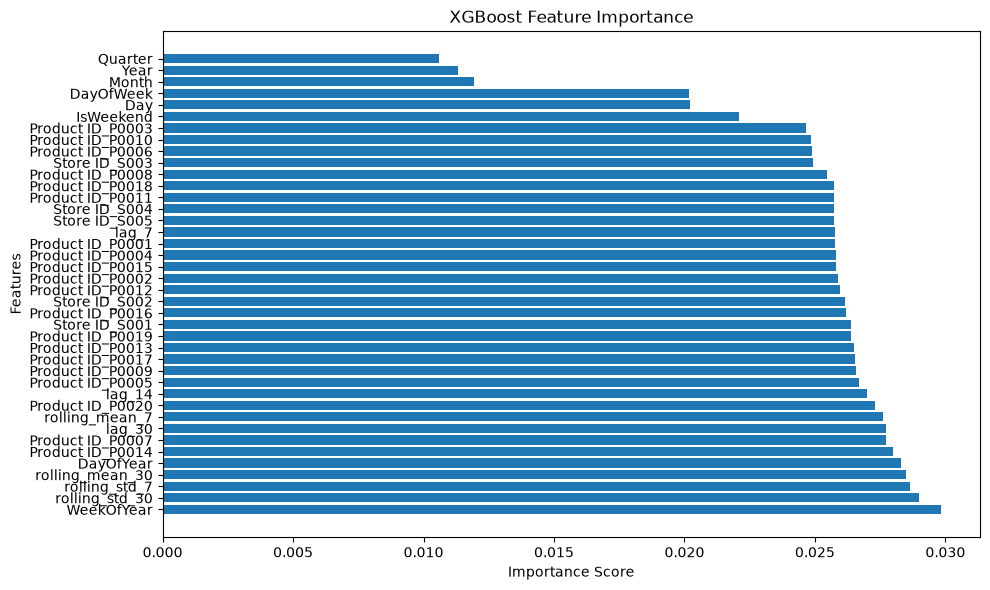

In [16]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["features"],
    importance["importance"]
)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [17]:
from pathlib import Path
import joblib

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    model_dir / "xgboost_experimental_model.pkl"
)

joblib.dump(
    list(x_train.columns),
    model_dir / "xgboost_feature_columns.pkl"
)

print("XGBoost experimental model saved successfully!")

XGBoost experimental model saved successfully!
